# Counting objects with LLMs: a vague prompt

---
*Introduction to Image Analysis Workshop*

*Stefania Marcotti (stefania.marcotti@crick.ac.uk) and Dave Barry (david.barry@crick.ac.uk)*

*Intro to using LLMs for image analysis*

*CC-BY-SA-4.0 license: creativecommons.org/licenses/by-sa/4.0/*

---


This notebook shows what happens when an LLM is asked to analyse an image with
a vague, under-specified prompt.

Each model is given the same prompt and must guess the answer to several
questions: what is in the image, whether objects are bright-on-dark or
dark-on-bright, whether they touch, and so on. Different models make different
guesses, so they produce different code, make different assumptions, and
sometimes write code that does not even run.


## The prompt

The following prompt was given to each model:

> I have a 2D multichannel fluorescence microscopy image of some cells that I need to analyse. Write Python code to count
> the cells. The code will go into an existing Jupyter notebook that loads the image into a variable called `img`.


## Import libraries


In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import ndimage as ndi
from skimage import color
from skimage import filters, morphology, segmentation, measure, feature
from skimage import io
from skimage.color import rgb2gray
from skimage.filters import gaussian, threshold_otsu
from skimage.measure import label
from skimage.morphology import opening, disk, remove_small_objects
from skimage.segmentation import watershed

## Open image

To run each model's code, we first load the image. The 4-channel field is made available as `img`, with its path stored in `filename`.


In [2]:
# read the 4-channel .tif file (nuclei, tubulin, actin, YAP/TAZ)
filename = '../../Data/idr0028/003003-10.tif'
img = io.imread(filename)

In [3]:
# print image dimensions
print('Image dimensions:', img.shape)

Image dimensions: (501, 667, 4)


## Model outputs

Each model was asked to write code; the code was then run against the same image. The cells below show exactly what each model returned.


### Claude Haiku 5-5

Image shape (H, W, C): (501, 667, 4)
Cell count: 27


C:\Users\davej\AppData\Local\Temp\ipykernel_17056\2907721135.py:35: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_objects(mask, min_size=MIN_AREA)
C:\Users\davej\AppData\Local\Temp\ipykernel_17056\2907721135.py:50: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  labels = morphology.re

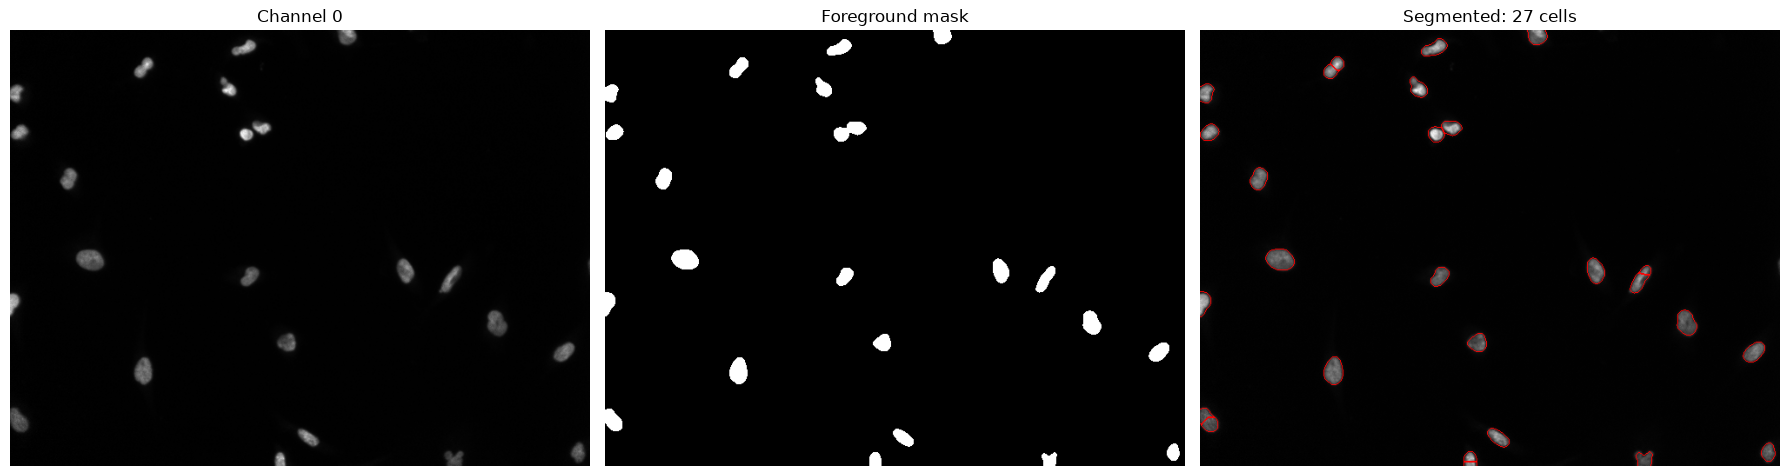

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from skimage import filters, morphology, measure, segmentation, feature

# ---------------- Settings ----------------
NUCLEI_CHANNEL = 0    # index of the channel to count (e.g. DAPI/Hoechst)
SMOOTH_SIGMA   = 2    # Gaussian smoothing (px) to suppress noise
MIN_AREA       = 30   # px; discard objects smaller than this (debris/noise)
MIN_DISTANCE   = 5    # px; minimum spacing between cell centres for splitting
# ------------------------------------------

# 1. Make the channel axis the last axis
arr = np.asarray(img)
if arr.ndim == 2:
    arr = arr[..., np.newaxis]
elif arr.ndim == 3:
    # The channel axis is assumed to be the smallest dimension
    arr = np.moveaxis(arr, int(np.argmin(arr.shape)), -1)
else:
    raise ValueError(f"Expected a 2D multichannel image, got shape {arr.shape}")

print("Image shape (H, W, C):", arr.shape)

# 2. Extract and normalise the nuclei channel
nuc = arr[..., NUCLEI_CHANNEL].astype(float)
nuc = (nuc - nuc.min()) / (nuc.max() - nuc.min() + 1e-12)

# 3. Smooth and threshold
smooth = filters.gaussian(nuc, sigma=SMOOTH_SIGMA)
thresh = filters.threshold_otsu(smooth)
mask = smooth > thresh
mask = ndi.binary_fill_holes(mask)
mask = morphology.opening(mask, morphology.disk(2))
mask = morphology.remove_small_objects(mask, min_size=MIN_AREA)

# 4. Split touching cells with a distance-transform watershed
distance = ndi.distance_transform_edt(mask)
coords = feature.peak_local_max(
    distance,
    min_distance=MIN_DISTANCE,
    labels=measure.label(mask),
    exclude_border=False,
)
markers = np.zeros(mask.shape, dtype=np.int32)
markers[tuple(coords.T)] = np.arange(1, len(coords) + 1)
labels = segmentation.watershed(-distance, markers, mask=mask)

# 5. Remove small fragments and relabel
labels = morphology.remove_small_objects(labels, min_size=MIN_AREA)
labels, _, _ = segmentation.relabel_sequential(labels)

cell_count = labels.max()
print(f"Cell count: {cell_count}")

# 6. Visualise the result
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(nuc, cmap="gray")
axes[0].set_title(f"Channel {NUCLEI_CHANNEL}")
axes[1].imshow(mask, cmap="gray")
axes[1].set_title("Foreground mask")
axes[2].imshow(segmentation.mark_boundaries(nuc, labels, color=(1, 0, 0)))
axes[2].set_title(f"Segmented: {cell_count} cells")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()


### Claude Sonnet 5-5

Image shape (501, 667, 4), assuming channel axis = 2


C:\Users\davej\AppData\Local\Temp\ipykernel_17056\3821721980.py:39: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_objects(mask, MIN_AREA)


Cell count: 24
Area (px²): median=280, min=164, max=565


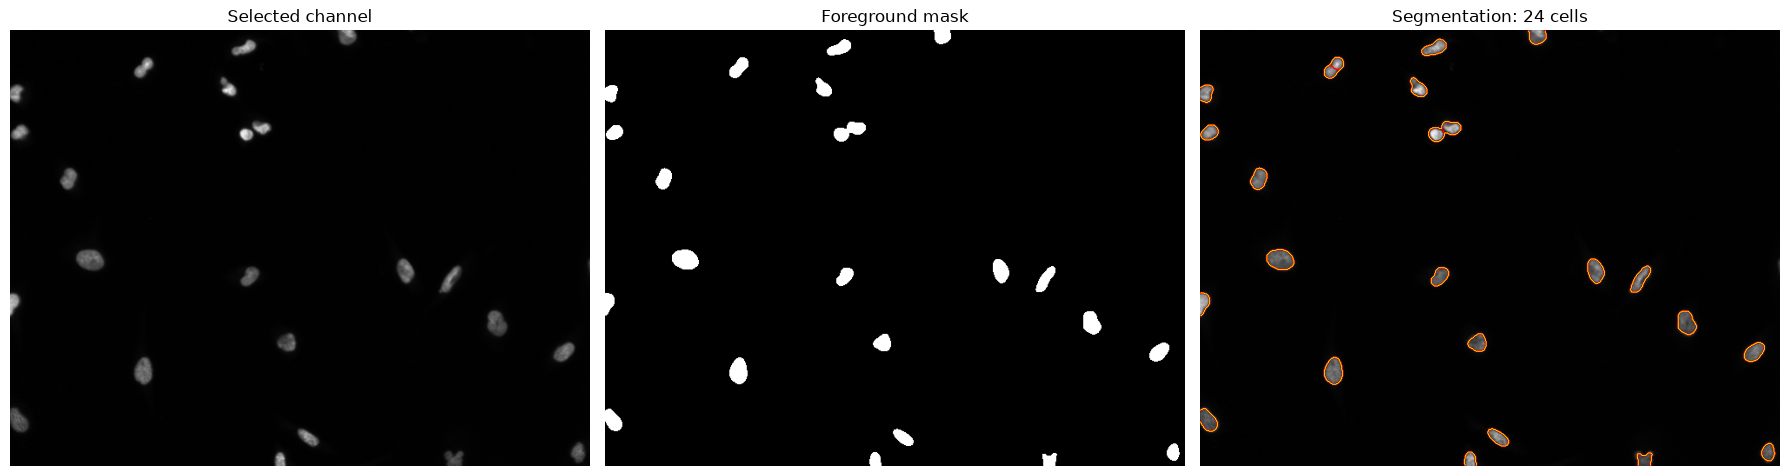

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from skimage import filters, morphology, measure, segmentation, feature, exposure

# ----------------- Parameters to adjust -----------------
NUCLEAR_CHANNEL = 0       # index of the channel with one blob per cell (e.g. DAPI)
SMOOTH_SIGMA = 2          # Gaussian blur (px); ~ 1/5 of a cell diameter
BG_SIGMA = 50             # large-scale background estimate (px); set None to skip
MIN_DISTANCE = 7          # min distance between cell centres (px); ~ cell radius
MIN_AREA = 30             # discard objects smaller than this (px²)
MAX_AREA = None           # discard objects larger than this (px²), None = no limit
REMOVE_BORDER_CELLS = False   # True to exclude cells touching the image edge
# ---------------------------------------------------------

# --- 1. Select the channel (handles channels-first or channels-last) ---
arr = np.asarray(img)
if arr.ndim == 3:
    ch_axis = int(np.argmin(arr.shape))          # channel axis = smallest dimension
    print(f"Image shape {arr.shape}, assuming channel axis = {ch_axis}")
    nuc = np.take(arr, NUCLEAR_CHANNEL, axis=ch_axis)
elif arr.ndim == 2:
    nuc = arr
else:
    raise ValueError(f"Expected a 2D (multichannel) image, got shape {arr.shape}")

nuc = nuc.astype(float)
nuc = (nuc - nuc.min()) / (np.ptp(nuc) + 1e-12)   # scale to 0–1

# --- 2. Denoise and remove uneven background ---
smooth = filters.gaussian(nuc, sigma=SMOOTH_SIGMA)
if BG_SIGMA:
    smooth = smooth - filters.gaussian(nuc, sigma=BG_SIGMA)
    smooth = np.clip(smooth, 0, None)

# --- 3. Threshold to get foreground mask ---
thresh = filters.threshold_otsu(smooth)
mask = smooth > thresh
mask = morphology.remove_small_objects(mask, MIN_AREA)
mask = ndi.binary_fill_holes(mask)

# --- 4. Split touching cells with a distance-transform watershed ---
distance = ndi.distance_transform_edt(mask)
distance = filters.gaussian(distance, sigma=1)
peaks = feature.peak_local_max(
    distance, min_distance=MIN_DISTANCE, labels=measure.label(mask), exclude_border=False
)
markers = np.zeros_like(mask, dtype=int)
markers[tuple(peaks.T)] = np.arange(1, len(peaks) + 1)
labels = segmentation.watershed(-distance, markers, mask=mask)

# --- 5. Filter objects by size / border ---
if REMOVE_BORDER_CELLS:
    labels = segmentation.clear_border(labels)

for region in measure.regionprops(labels):
    too_small = region.area < MIN_AREA
    too_big = MAX_AREA is not None and region.area > MAX_AREA
    if too_small or too_big:
        labels[labels == region.label] = 0

labels, _, _ = segmentation.relabel_sequential(labels)
n_cells = labels.max()
areas = [r.area for r in measure.regionprops(labels)]

print(f"Cell count: {n_cells}")
print(f"Area (px²): median={np.median(areas):.0f}, "
      f"min={np.min(areas):.0f}, max={np.max(areas):.0f}")

# --- 6. Visual check ---
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharex=True, sharey=True)
axes[0].imshow(exposure.rescale_intensity(nuc, out_range=(0, 1)), cmap="gray")
axes[0].set_title("Selected channel")
axes[1].imshow(mask, cmap="gray")
axes[1].set_title("Foreground mask")
axes[2].imshow(nuc, cmap="gray")
axes[2].contour(labels > 0, levels=[0.5], colors="yellow", linewidths=0.5)
axes[2].imshow(np.ma.masked_equal(segmentation.find_boundaries(labels), 0),
               cmap="autumn", alpha=1)
axes[2].set_title(f"Segmentation: {n_cells} cells")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()


### Claude Opus 5-5

Image shape (501, 667, 4); using axis 2 as channels (4 channels).
Number of cells (nuclei) detected: 23


,label,area,centroid-0,centroid-1,eccentricity,mean_intensity
count,23.00000,23.000000,23.000000,23.000000,23.000000,23.000000
mean,12.00000,334.869565,260.412727,284.028221,0.714993,0.613359
std,6.78233,95.215690,165.052417,203.058683,0.152409,0.092138
min,1.00000,201.000000,6.959866,4.428571,0.332816,0.428968
25%,6.50000,276.000000,114.318207,122.608807,0.671145,0.545493
50%,12.00000,311.000000,282.837748,275.407285,0.738930,0.604407
75%,17.50000,371.500000,380.539461,420.961627,0.790847,0.690058
max,23.00000,600.000000,493.139303,653.152542,0.937847,0.763210


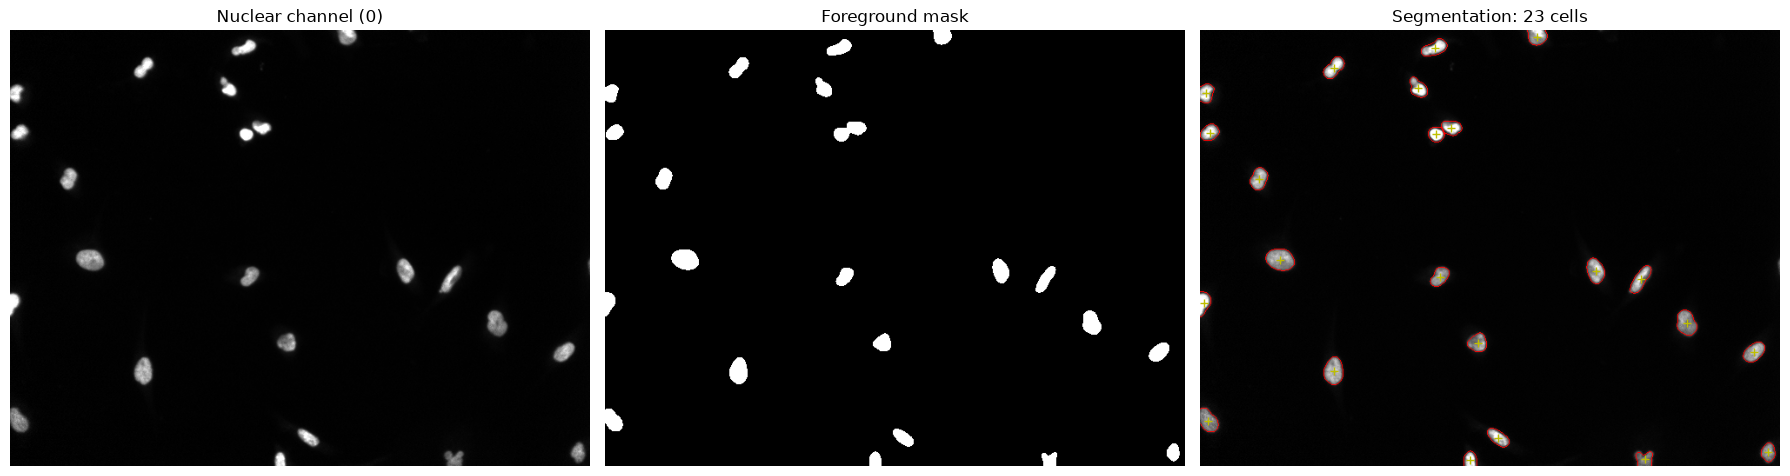

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from skimage import filters, segmentation, measure, feature, exposure

# ----------------------------- Parameters ---------------------------------
NUCLEAR_CHANNEL   = 0      # index of the nuclear stain channel (DAPI/Hoechst)
CHANNEL_AXIS      = None   # None = auto-detect (smallest axis); or set 0 / -1 explicitly
SMOOTH_SIGMA      = 2      # Gaussian blur (pixels) before thresholding
MIN_NUCLEUS_AREA  = 50     # objects smaller than this (pixels) are discarded as debris
MIN_DISTANCE      = 7      # min distance (pixels) between nucleus centres; ~ nucleus radius
EXCLUDE_BORDER    = False  # True = don't count nuclei touching the image edge
# --------------------------------------------------------------------------


def get_channel(image, channel, channel_axis=None):
    """Extract a single 2D channel from a 2D or multichannel image."""
    image = np.squeeze(np.asarray(image))
    if image.ndim == 2:
        return image.astype(float)
    if image.ndim != 3:
        raise ValueError(f"Expected a 2D multichannel image, got shape {image.shape}")
    if channel_axis is None:
        channel_axis = int(np.argmin(image.shape))  # channels = smallest axis
    print(f"Image shape {image.shape}; using axis {channel_axis} as channels "
          f"({image.shape[channel_axis]} channels).")
    return np.take(image, channel, axis=channel_axis).astype(float)


def remove_small_labels(label_img, min_area):
    """Remove labelled objects with area < min_area."""
    sizes = np.bincount(label_img.ravel())
    too_small = sizes < min_area
    too_small[0] = False  # keep background as-is
    label_img = label_img.copy()
    label_img[too_small[label_img]] = 0
    return label_img


# 1. Extract and normalise the nuclear channel (robust to outlier pixels)
nuc = get_channel(img, NUCLEAR_CHANNEL, CHANNEL_AXIS)
lo, hi = np.percentile(nuc, (0.5, 99.8))
nuc = exposure.rescale_intensity(nuc, in_range=(lo, hi), out_range=(0, 1))

# 2. Smooth and threshold (Otsu) to get a foreground mask
smooth = filters.gaussian(nuc, sigma=SMOOTH_SIGMA)
mask = smooth > filters.threshold_otsu(smooth)
mask = ndi.binary_fill_holes(mask)
mask = remove_small_labels(measure.label(mask), MIN_NUCLEUS_AREA) > 0

# 3. Split touching nuclei: watershed on the distance transform
distance = ndi.distance_transform_edt(mask)
distance = filters.gaussian(distance, sigma=1)  # suppress spurious peaks
peaks = feature.peak_local_max(
    distance,
    min_distance=MIN_DISTANCE,
    labels=measure.label(mask),
    exclude_border=False,
)
markers = np.zeros(mask.shape, dtype=np.int32)
markers[tuple(peaks.T)] = np.arange(1, len(peaks) + 1)
labels = segmentation.watershed(-distance, markers, mask=mask)

# 4. Clean up: drop small fragments, optionally edge-touching nuclei
labels = remove_small_labels(labels, MIN_NUCLEUS_AREA)
if EXCLUDE_BORDER:
    labels = segmentation.clear_border(labels)
labels, _, _ = segmentation.relabel_sequential(labels)

n_cells = int(labels.max())
print(f"Number of cells (nuclei) detected: {n_cells}")

# 5. Per-cell measurements (handy for QC / downstream analysis)
props = measure.regionprops_table(
    labels, intensity_image=nuc,
    properties=("label", "area", "centroid", "eccentricity", "mean_intensity"),
)
try:
    import pandas as pd
    cell_table = pd.DataFrame(props)
    display(cell_table.describe())
except ImportError:
    cell_table = props

# 6. Visual check
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(nuc, cmap="gray")
axes[0].set_title(f"Nuclear channel ({NUCLEAR_CHANNEL})")
axes[1].imshow(mask, cmap="gray")
axes[1].set_title("Foreground mask")
axes[2].imshow(segmentation.mark_boundaries(nuc, labels, color=(1, 0, 0)))
centroids = np.array([r.centroid for r in measure.regionprops(labels)])
if len(centroids):
    axes[2].plot(centroids[:, 1], centroids[:, 0], "y+", markersize=6)
axes[2].set_title(f"Segmentation: {n_cells} cells")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()


### Mistral Small 4

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import filters, morphology, measure, segmentation
from scipy import ndimage as ndi

# Assuming `img` is already loaded as a 2D multichannel array
# Example: img.shape = (height, width, channels)

# Step 1: Select the channel with the best contrast (e.g., channel 0)
channel = img[:, :, 0]  # Adjust channel index as needed

# Step 2: Preprocess the image
# Enhance contrast (e.g., using CLAHE)
from skimage.exposure import equalize_adapthist
channel_eq = equalize_adapthist(channel, kernel_size=None, clip_limit=0.03)

# Step 3: Denoise (e.g., using Gaussian blur)
channel_blur = filters.gaussian(channel_eq, sigma=1)

# Step 4: Thresholding (Otsu's method)
threshold = filters.threshold_otsu(channel_blur)
binary = channel_blur > threshold

# Step 5: Clean up the binary image
# Remove small objects
binary_clean = morphology.remove_small_objects(binary, min_size=100)
binary_clean = morphology.remove_small_holes(binary_clean, area_threshold=100)

# Step 6: Separate touching cells (Watershed)
# Compute distance to background
distance = ndi.distance_transform_edt(binary_clean)
local_max = morphology.peak_local_max(distance, min_distance=10, labels=binary_clean)
markers = measure.label(local_max)
labels = segmentation.watershed(-distance, markers, mask=binary_clean)

# Step 7: Count cells
num_cells = len(np.unique(labels)) - 1  # Subtract 1 for background (label 0)

# Visualize results
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
axes[0, 0].imshow(channel, cmap='gray')
axes[0, 0].set_title('Original Channel')
axes[0, 1].imshow(channel_eq, cmap='gray')
axes[0, 1].set_title('Contrast Enhanced')
axes[0, 2].imshow(binary, cmap='gray')
axes[0, 2].set_title('Thresholded')
axes[1, 0].imshow(binary_clean, cmap='gray')
axes[1, 0].set_title('Cleaned Binary')
axes[1, 1].imshow(labels, cmap='nipy_spectral')
axes[1, 1].set_title('Segmented Cells')
axes[1, 2].text(0.5, 0.5, f'Number of Cells: {num_cells}',
               fontsize=14, ha='center')
axes[1, 2].axis('off')
plt.tight_layout()
plt.show()

print(f"Number of cells: {num_cells}")


C:\Users\davej\AppData\Local\Temp\ipykernel_17056\3056193883.py:26: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  binary_clean = morphology.remove_small_objects(binary, min_size=100)
C:\Users\davej\AppData\Local\Temp\ipykernel_17056\3056193883.py:27: FutureWarning: Parameter `area_threshold` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_holes`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  binary_clean 

AttributeError: module 'skimage.morphology' has no attribute 'peak_local_max'

### Mistral Large 4

Detected shape (H,W,C): (501, 667, 4). Using channel 0


C:\Users\davej\AppData\Local\Temp\ipykernel_17056\118297354.py:54: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  binary_clean = morphology.remove_small_objects(binary_mask, min_size=MIN_CELL_SIZE)
C:\Users\davej\AppData\Local\Temp\ipykernel_17056\118297354.py:56: FutureWarning: Parameter `area_threshold` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_holes`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  


RESULTS:
  Threshold value: 0.4629
  Seeds found: 22
  Valid cells counted: 22
  Rejected regions (too small/large): 0


ValueError: 'cyan' is not a valid value for cmap. Did you mean one of: 'ocean', 'ocean_r'?
See `matplotlib.bivar_colormaps()` and `matplotlib.multivar_colormaps()` for bivariate and multivariate colormaps

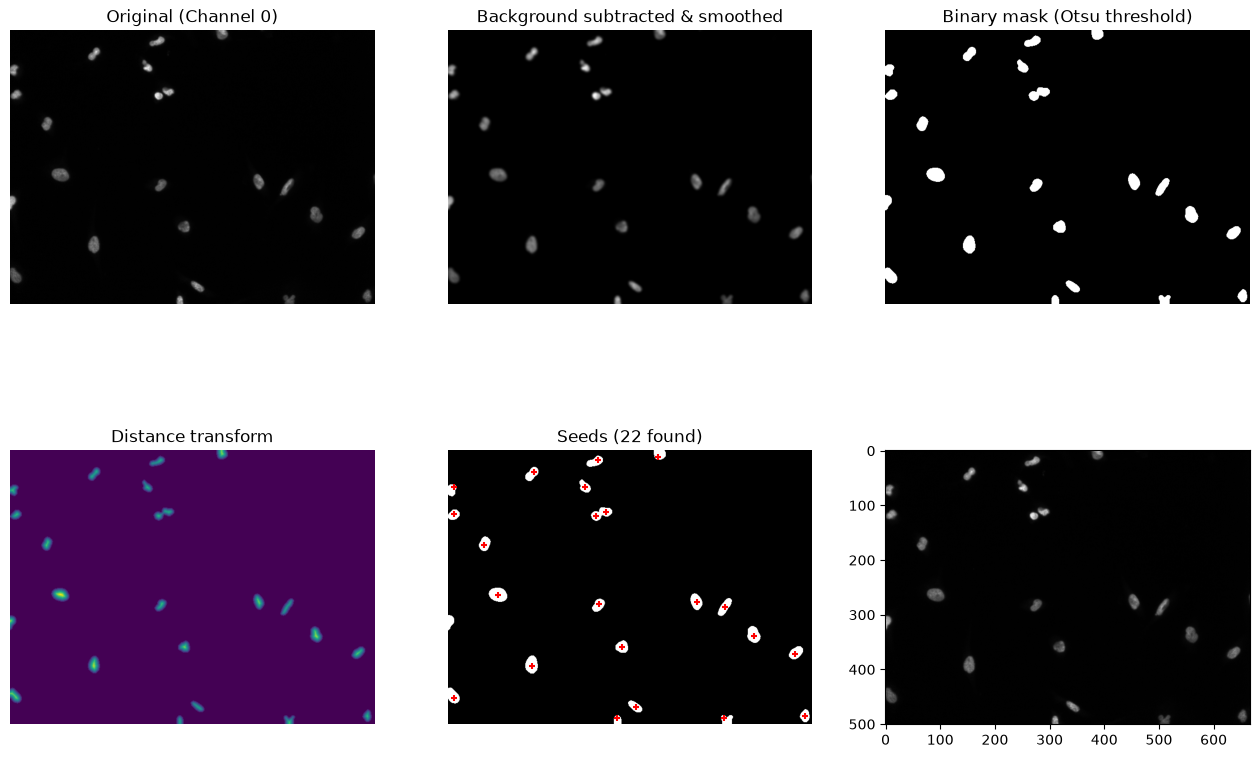

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import filters, morphology, segmentation, measure, feature, exposure
from scipy import ndimage as ndi

# ==================== CONFIGURATION ====================
# Adjust these parameters based on your image:
CHANNEL = 0              # Which channel to use (0-indexed). Usually the nuclear stain (DAPI/Hoechst)
MIN_CELL_SIZE = 80       # Minimum cell area in pixels (removes noise/debris)
MAX_CELL_SIZE = 10000    # Maximum cell area (removes large clumps)
MIN_DISTANCE = 12        # Minimum pixels between cell centers (for separating touching cells)
SIGMA_SMOOTH = 1.5       # Gaussian smoothing sigma (reduces noise before thresholding)
# =======================================================

# 1. Handle multichannel image and extract the channel to analyze
if img.ndim == 3:
    # Auto-detect if channels are first (C,H,W) or last (H,W,C)
    if img.shape[0] <= 5 and img.shape[0] < img.shape[1]:
        # Likely (C, H, W) format
        img_channel = img[CHANNEL]
        print(f"Detected shape (C,H,W): {img.shape}. Using channel {CHANNEL}")
    else:
        # Likely (H, W, C) format
        img_channel = img[..., CHANNEL]
        print(f"Detected shape (H,W,C): {img.shape}. Using channel {CHANNEL}")
else:
    img_channel = img
    print(f"Single channel image: {img.shape}")

# Convert to float and normalize to 0-1 range for processing
img_float = img_channel.astype(np.float32)
if img_float.max() > 0:
    img_float = (img_float - img_float.min()) / (img_float.max() - img_float.min())

# 2. Preprocessing
# Background subtraction using a large Gaussian (approximates rolling-ball)
background = filters.gaussian(img_float, sigma=50, preserve_range=True)
img_bg = img_float - background
img_bg[img_bg < 0] = 0

# Smooth to reduce noise
img_smooth = filters.gaussian(img_bg, sigma=SIGMA_SMOOTH, preserve_range=True)

# Contrast stretching for better thresholding
p2, p98 = np.percentile(img_smooth, (2, 98))
img_rescaled = exposure.rescale_intensity(img_smooth, in_range=(p2, p98))

# 3. Thresholding (Otsu's automatic method)
threshold = filters.threshold_otsu(img_rescaled)
binary_mask = img_rescaled > threshold

# 4. Clean the binary mask
# Remove small objects (noise)
binary_clean = morphology.remove_small_objects(binary_mask, min_size=MIN_CELL_SIZE)
# Fill holes inside cells (if any)
binary_clean = morphology.remove_small_holes(binary_clean, area_threshold=MIN_CELL_SIZE)
# Smooth boundaries with morphological opening
binary_clean = morphology.binary_opening(binary_clean, morphology.disk(2))

# 5. Separate touching cells using Watershed algorithm
# Distance transform: distance of each foreground pixel to the background
distance = ndi.distance_transform_edt(binary_clean)

# Find local maxima as seeds for the watershed
coords = feature.peak_local_max(distance, min_distance=MIN_DISTANCE, labels=binary_clean)
seeds = np.zeros(distance.shape, dtype=bool)
seeds[tuple(coords.T)] = True
markers, num_seeds = ndi.label(seeds)

# Apply watershed to separate touching objects
labels = segmentation.watershed(-distance, markers, mask=binary_clean)

# 6. Filter by size and count
regions = measure.regionprops(labels)
valid_cells = [r for r in regions if MIN_CELL_SIZE <= r.area <= MAX_CELL_SIZE]
cell_count = len(valid_cells)

print(f"\n{'='*50}")
print(f"RESULTS:")
print(f"  Threshold value: {threshold:.4f}")
print(f"  Seeds found: {num_seeds}")
print(f"  Valid cells counted: {cell_count}")
print(f"  Rejected regions (too small/large): {len(regions) - cell_count}")
print(f"{'='*50}")

# 7. Visualization
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

# Original channel
axes[0, 0].imshow(img_channel, cmap='gray')
axes[0, 0].set_title(f'Original (Channel {CHANNEL})')
axes[0, 0].axis('off')

# Preprocessed
axes[0, 1].imshow(img_smooth, cmap='gray')
axes[0, 1].set_title('Background subtracted & smoothed')
axes[0, 1].axis('off')

# Binary mask
axes[0, 2].imshow(binary_clean, cmap='gray')
axes[0, 2].set_title(f'Binary mask (Otsu threshold)')
axes[0, 2].axis('off')

# Distance transform
axes[1, 0].imshow(distance, cmap='viridis')
axes[1, 0].set_title('Distance transform')
axes[1, 0].axis('off')

# Seeds
axes[1, 1].imshow(binary_clean, cmap='gray')
axes[1, 1].scatter(coords[:, 1], coords[:, 0], c='red', s=20, marker='+')
axes[1, 1].set_title(f'Seeds ({num_seeds} found)')
axes[1, 1].axis('off')

# Final result with boundaries and centroids
axes[1, 2].imshow(img_channel, cmap='gray')
# Draw cell boundaries in cyan
boundaries = segmentation.find_boundaries(labels, mode='thick')
axes[1, 2].imshow(np.ma.masked_where(~boundaries, boundaries), cmap='cyan', alpha=0.6)
# Mark centroids in red
for region in valid_cells:
    y, x = region.centroid
    axes[1, 2].plot(x, y, 'r+', markersize=10, markeredgewidth=2)
axes[1, 2].set_title(f'Detected cells: {cell_count}')
axes[1, 2].axis('off')

plt.tight_layout()
plt.show()

# Optional: Save the labeled image for downstream analysis
# labeled_image = labels  # Each cell has a unique integer ID


### Mistral Codestral

H:\GitRepos\Pages\crick-introduction-to-image-analysis\introduction-to-image-analysis\.pixi\envs\intro-ia\Lib\site-packages\skimage\filters\rank\generic.py:332: UserWarning: Bad rank filter performance is expected due to a large number of bins (2083), equivalent to an approximate bitdepth of 11.0.
  image, footprint, out, mask, n_bins = _preprocess_input(


C:\Users\davej\AppData\Local\Temp\ipykernel_17056\3442525935.py:62: FutureWarning: `binary_closing` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.closing` instead.
  binary = morphology.binary_closing(binary, morphology.disk(3))
C:\Users\davej\AppData\Local\Temp\ipykernel_17056\3442525935.py:63: FutureWarning: `binary_opening` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.opening` instead.
  binary = morphology.binary_opening(binary, morphology.disk(2))
C:\Users\davej\AppData\Local\Temp\ipykernel_17056\3442525935.py:66: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed small

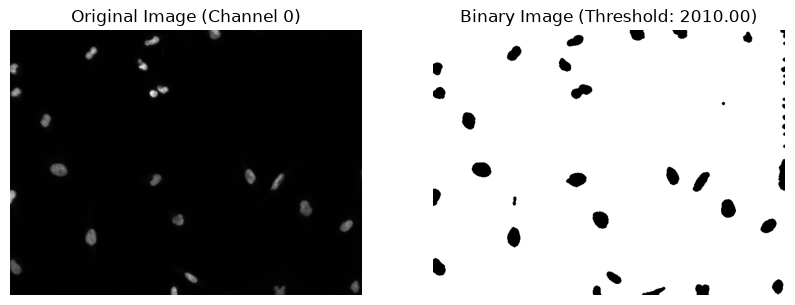

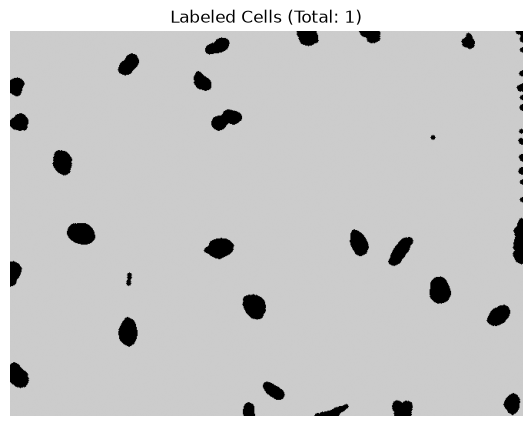

Total number of cells detected: 1


In [9]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import filters, measure, morphology, segmentation
from scipy import ndimage

def count_cells(img, channel=0, threshold_method='otsu', min_size=10, max_size=None,
                show_steps=False, save_figures=False):
    """
    Count cells in a 2D multichannel fluorescence microscopy image.

    Parameters:
    - img: Input image (numpy array)
    - channel: Which channel to use for segmentation (default: 0)
    - threshold_method: Thresholding method ('otsu', 'yen', 'li', 'mean', 'minimum', 'triangle')
    - min_size: Minimum object size to consider as a cell (pixels)
    - max_size: Maximum object size to consider as a cell (pixels)
    - show_steps: Whether to display intermediate processing steps
    - save_figures: Whether to save intermediate figures

    Returns:
    - labeled_cells: Labeled image of identified cells
    - cell_count: Total number of cells
    """

    # Select the specified channel (assuming img is a 3D array: height x width x channels)
    if len(img.shape) == 3:
        img_channel = img[:, :, channel]
    else:
        img_channel = img

    # Display original image
    if show_steps or save_figures:
        plt.figure(figsize=(10, 5))
        plt.subplot(1, 2, 1)
        plt.imshow(img_channel, cmap='gray')
        plt.title('Original Image (Channel {})'.format(channel))
        plt.axis('off')

    # Apply background subtraction (simple method)
    background = filters.rank.mean(img_channel, morphology.disk(50))
    img_subtracted = img_channel - background

    # Apply thresholding
    if threshold_method == 'otsu':
        threshold = filters.threshold_otsu(img_subtracted)
    elif threshold_method == 'yen':
        threshold = filters.threshold_yen(img_subtracted)
    elif threshold_method == 'li':
        threshold = filters.threshold_li(img_subtracted)
    elif threshold_method == 'mean':
        threshold = filters.threshold_mean(img_subtracted)
    elif threshold_method == 'minimum':
        threshold = filters.threshold_minimum(img_subtracted)
    elif threshold_method == 'triangle':
        threshold = filters.threshold_triangle(img_subtracted)
    else:
        raise ValueError("Invalid threshold method")

    binary = img_subtracted > threshold

    # Apply morphological operations to clean up the image
    binary = morphology.binary_closing(binary, morphology.disk(3))
    binary = morphology.binary_opening(binary, morphology.disk(2))

    # Remove small objects
    binary = morphology.remove_small_objects(binary, min_size=min_size)

    # Remove large objects if max_size is specified
    if max_size is not None:
        binary = morphology.remove_small_objects(~binary, min_size=max_size)
        binary = ~binary

    # Label connected components
    labeled_cells, num_cells = ndimage.label(binary)

    # Display processing steps if requested
    if show_steps or save_figures:
        plt.subplot(1, 2, 2)
        plt.imshow(binary, cmap='gray')
        plt.title('Binary Image (Threshold: {:.2f})'.format(threshold))
        plt.axis('off')

        if show_steps:
            plt.show()

        if save_figures:
            plt.savefig('cell_segmentation_steps.png', dpi=300, bbox_inches='tight')
            plt.close()

    # Display labeled cells
    if show_steps or save_figures:
        plt.figure(figsize=(10, 5))
        plt.imshow(labeled_cells, cmap='nipy_spectral')
        plt.title('Labeled Cells (Total: {})'.format(num_cells))
        plt.axis('off')

        if show_steps:
            plt.show()

        if save_figures:
            plt.savefig('labeled_cells.png', dpi=300, bbox_inches='tight')
            plt.close()

    return labeled_cells, num_cells

# Example usage:
# Assuming your image is loaded into 'img' variable
# You can adjust parameters as needed
labeled_cells, cell_count = count_cells(
    img,
    channel=0,  # Use the first channel (adjust if needed)
    threshold_method='otsu',  # Try different methods if needed
    min_size=20,  # Minimum cell size in pixels
    max_size=None,  # Set if you want to exclude very large objects
    show_steps=True,  # Set to False to hide intermediate steps
    save_figures=False  # Set to True to save figures
)

print(f"Total number of cells detected: {cell_count}")


### Deepseek Flash

Estimated cell count: 26


C:\Users\davej\AppData\Local\Temp\ipykernel_17056\888010737.py:43: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_objects(mask, min_size=min_cell_area)
C:\Users\davej\AppData\Local\Temp\ipykernel_17056\888010737.py:44: FutureWarning: Parameter `area_threshold` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_holes`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morpholo

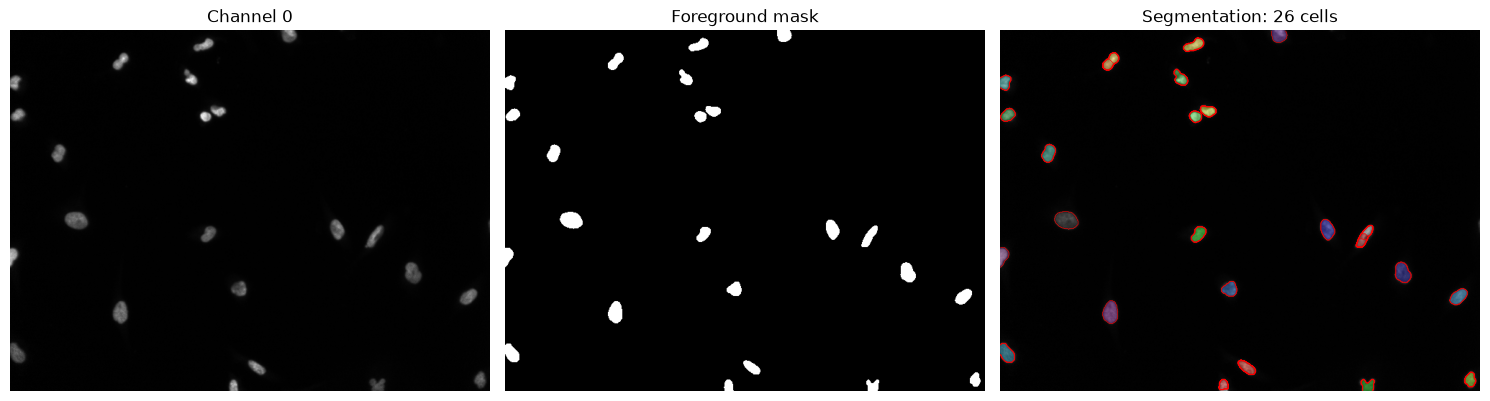

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from skimage import filters, morphology, segmentation, measure, exposure
from skimage.feature import peak_local_max

# ---------- parameters to tune ----------
nucleus_channel = 0        # channel containing nuclei/cells, e.g. DAPI
sigma = 1.0                # Gaussian smoothing
min_cell_area = 50         # minimum object size in pixels
max_cell_area = None       # e.g. 5000; None = no upper limit
min_peak_distance = 5      # roughly half the minimum nucleus radius
invert_intensity = False   # True if cells are dark on a bright background
# ----------------------------------------

def get_2d_channel(img, channel=0):
    """Return a single 2D channel from 2D or multichannel image."""
    a = np.asarray(img)
    if a.ndim == 2:
        return a.astype(float)
    if a.ndim != 3:
        raise ValueError(f"Expected 2D or 3D image, got shape {a.shape}")

    # Common cases: H,W,C or C,H,W
    if a.shape[-1] <= 5:       # H, W, C
        return a[..., channel].astype(float)
    elif a.shape[0] <= 5:      # C, H, W
        return a[channel].astype(float)
    else:
        raise ValueError("Could not determine channel axis; edit get_2d_channel manually.")

ch = get_2d_channel(img, nucleus_channel)

if invert_intensity:
    ch = ch.max() - ch

# Smooth and threshold
ch_smooth = filters.gaussian(ch, sigma=sigma, preserve_range=True)
thr = filters.threshold_otsu(ch_smooth)
mask = ch_smooth > thr

# Remove noise/small holes
mask = morphology.remove_small_objects(mask, min_size=min_cell_area)
mask = morphology.remove_small_holes(mask, area_threshold=min_cell_area)
mask = morphology.binary_opening(mask, morphology.disk(1))

# Distance transform + watershed to separate touching nuclei
distance = ndi.distance_transform_edt(mask)
coords = peak_local_max(
    distance,
    min_distance=min_peak_distance,
    labels=mask,
    exclude_border=False
)

markers = np.zeros(distance.shape, dtype=np.int32)
if len(coords) > 0:
    markers[tuple(coords.T)] = np.arange(1, len(coords) + 1)

labels = segmentation.watershed(-distance, markers, mask=mask)

# Filter objects by area
props = measure.regionprops(labels)
keep = []
for p in props:
    if p.area >= min_cell_area and (max_cell_area is None or p.area <= max_cell_area):
        keep.append(p.label)

# Relabel only kept objects
labels_clean = np.zeros_like(labels, dtype=np.int32)
for new_id, old_id in enumerate(keep, start=1):
    labels_clean[labels == old_id] = new_id

cell_count = len(keep)
print(f"Estimated cell count: {cell_count}")

# Visualization
disp = exposure.rescale_intensity(ch, out_range=(0, 1))

fig, ax = plt.subplots(1, 3, figsize=(15, 5))

ax[0].imshow(disp, cmap="gray")
ax[0].set_title(f"Channel {nucleus_channel}")

ax[1].imshow(mask, cmap="gray")
ax[1].set_title("Foreground mask")

ax[2].imshow(disp, cmap="gray")
ax[2].imshow(
    np.ma.masked_where(labels_clean == 0, labels_clean),
    cmap="nipy_spectral",
    alpha=0.35
)
ax[2].contour(labels_clean, colors="red", linewidths=0.4)
ax[2].set_title(f"Segmentation: {cell_count} cells")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()


### Deepseek V4 Pro

In [11]:
import numpy as np
from scipy import ndimage as ndi
from skimage import filters, morphology, segmentation
from skimage.feature import peak_local_max

# --- Parameters you may need to tune ---
channel = None          # Set to e.g. 0 to use a specific channel; None uses max projection
sigma = 1.5             # Gaussian smoothing sigma
min_size = 100          # Minimum cell area in pixels
min_distance = 10       # Minimum distance between cell centres in pixels

img = np.asarray(img)

# --- Reduce multichannel image to a single 2D image ---
if img.ndim == 3:
    # Detect channels-first (C,H,W) vs channels-last (H,W,C)
    if img.shape[0] <= 10 and img.shape[-1] > 10:
        # channels-first
        if channel is None:
            image_2d = np.max(img, axis=0)
        else:
            image_2d = img[channel]
    elif img.shape[-1] <= 10 and img.shape[0] > 10:
        # channels-last
        if channel is None:
            image_2d = np.max(img, axis=2)
        else:
            image_2d = img[..., channel]
    else:
        # Ambiguous: assume channels-last if last axis is the smallest
        if img.shape[-1] <= img.shape[0]:
            if channel is None:
                image_2d = np.max(img, axis=2)
            else:
                image_2d = img[..., channel]
        else:
            if channel is None:
                image_2d = np.max(img, axis=0)
            else:
                image_2d = img[channel]
elif img.ndim == 2:
    image_2d = img
else:
    raise ValueError(f"Expected 2D or 3D image, got shape {img.shape}")

# --- Normalise to [0, 1] ---
image_2d = image_2d.astype(np.float32)
image_2d = (image_2d - image_2d.min()) / (image_2d.max() - image_2d.min() + 1e-8)

# --- Smooth and threshold ---
image_smooth = filters.gaussian(image_2d, sigma=sigma)
thresh = filters.threshold_otsu(image_smooth)
mask = image_smooth > thresh       # Use < if cells are dark on bright background

# --- Clean mask ---
mask = morphology.remove_small_objects(mask, min_size=min_size)
mask = ndi.binary_fill_holes(mask)
mask = morphology.remove_small_objects(mask, min_size=min_size)

# --- Watershed to split touching cells ---
if mask.sum() > 0:
    distance = ndi.distance_transform_edt(mask)
    distance_smooth = filters.gaussian(distance, sigma=sigma * 1.5)

    coords = peak_local_max(distance_smooth, min_distance=min_distance, exclude_border=False)
    markers = np.zeros(distance_smooth.shape, dtype=np.int32)
    markers[tuple(coords.T)] = np.arange(1, len(coords) + 1)

    labels = segmentation.watershed(-distance_smooth, markers, mask=mask)
    n_cells = labels.max()
else:
    labels = np.zeros(image_2d.shape, dtype=np.int32)
    n_cells = 0

print(f"Number of cells: {n_cells}")
# labels now contains the labelled cell segmentation image


Number of cells: 47


C:\Users\davej\AppData\Local\Temp\ipykernel_17056\1349103721.py:56: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_objects(mask, min_size=min_size)
C:\Users\davej\AppData\Local\Temp\ipykernel_17056\1349103721.py:58: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remo

## Results

| Model | Count |
| --- | --- |
| Claude Haiku 5-5 | 27 |
| Claude Sonnet 5-5 | 24 |
| Claude Opus 5-5 | 23 |
| Mistral Small 4 | error |
| Mistral Large 4 | error |
| Mistral Codestral | 1 |
| Deepseek Flash | 26 |
| Deepseek V4 Pro | 47 |


## Conclusion

A vague prompt produces uncontrolled variance. The models are not necessarily
wrong, but they are guessing, so the numbers they return cannot be trusted or
compared.

If you want reliable, consistent code, describe your data and your task
precisely. The next notebook shows what happens when you do.
